In [69]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd 
import numpy as np 
import sys
sys.path.append("..")

from src import data_toolkit as dt
from src import portfolio_toolkit as pt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [70]:
from pathlib import Path

### Single-Date Test

Before running the full walk-forward backtest, we first test the Black–Litterman framework on a single historical date.

In [71]:
processed_dir = Path("../data/processed")
rets = pd.read_csv(
    processed_dir /"ff12_returns.csv",
    index_col = 0
)
weights = pd.read_csv(
    processed_dir/"ff12_market_weights.csv",
    index_col  = 0
)
rf = pd.read_csv(
    processed_dir/"risk_free.csv",
    index_col = 0
).squeeze("columns")
forward_12m_excess = pd.read_csv(
    processed_dir/"forward_12m_excess_target.csv",
    index_col = 0
)

In [72]:
test_date = "2000-12"
estimation_window = rets.loc[:test_date].tail(60)

In [73]:
estimation_window.shape

(60, 12)

In [74]:
sigma_monthly = pt.shrinkage_cov(estimation_window, delta = 0.5)
sigma = sigma_monthly * 12

In [75]:
w_mkt = weights.loc[test_date].round(3)
pi = pt.implied_rets(delta = 2.5, sigma = sigma ,w =  w_mkt)

In [76]:
pi

NoDur    0.041046
Durbl    0.056861
Manuf    0.057122
Enrgy    0.045237
Chems    0.043507
BusEq    0.115434
Telcm    0.061519
Utils    0.024564
Shops    0.053783
Hlth     0.047780
Money    0.068336
Other    0.057501
Name: Implied Returns, dtype: float64

### View Linkage Matrix

Since we generate an absolute return view for each of the 12 industries, the linkage matrix is the identity matrix:

In [77]:
P = pd.DataFrame(
    np.eye(12),
    index=rets.columns,
    columns=rets.columns
)

In [78]:
P

,NoDur,Durbl,Manuf,Enrgy,Chems,BusEq,Telcm,Utils,Shops,Hlth,Money,Other
NoDur,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Durbl,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Manuf,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Enrgy,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Chems,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BusEq,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
Telcm,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
Utils,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
Shops,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
Hlth,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


We introduce view matrix, check whether the mechanics work:

In [79]:
Q = pi.copy()
Q["Enrgy"] = pi["Enrgy"] + 0.02

In [80]:
mu_bl, sigma_bl = pt.bl(
    w_prior=w_mkt,
    sigma_prior=sigma,
    p=P,
    q=Q,
    delta=2.5,
    tau=1/60
)

In [81]:
comparison = pd.DataFrame({
    "Prior": pi,
    "View": Q,
    "BL Posterior": mu_bl["rets"]
})

comparison

,Prior,View,BL Posterior
NoDur,0.041046,0.041046,0.041448
Durbl,0.056861,0.056861,0.057555
Manuf,0.057122,0.057122,0.058033
Enrgy,0.045237,0.065237,0.053354
Chems,0.043507,0.043507,0.044463
BusEq,0.115434,0.115434,0.116610
Telcm,0.061519,0.061519,0.061561
Utils,0.024564,0.024564,0.025811
Shops,0.053783,0.053783,0.054281
Hlth,0.047780,0.047780,0.048132


As one can clearly notice, Enrgy sector captured our views with some uncertainty;
That procedure also effcets the posterior covariance - as we deal with extra uncertainty when integrating our views -> that is seen below:

In [82]:
pd.DataFrame({
    "Prior Variance": np.diag(sigma),
    "BL Variance": np.diag(sigma_bl)
}, index=rets.columns)

,Prior Variance,BL Variance
NoDur,0.025764,0.025922
Durbl,0.041741,0.041996
Manuf,0.032709,0.032891
Enrgy,0.035851,0.036094
Chems,0.029954,0.030140
BusEq,0.105754,0.106452
Telcm,0.044360,0.044648
Utils,0.023398,0.023568
Shops,0.032925,0.033123
Hlth,0.030795,0.031005


### Portfolio Weight Construction

The unconstrained mean–variance solution does not generally sum to one. Simply normalizing it would change the solution and remove the effect of risk aversion. It only works for Sharpe Maximizing Scenario, where we dont care about risk-aversion, and both numerator and denominator scale proportionally and cancel.

Therefore, portfolio weights are obtained by solving the mean–variance problem directly ***subject*** to full investment and weight constraints.

***I have added the function into a toolkit (for Constrained Mean_Variance optimal portfolio weights construction):***

```python
def w_mv(delta, sigma, mu, max_weight=0.30):
    """
    Computes constrained mean-variance optimal portfolio weights.

    Maximizes:
        w.T @ mu - delta/2 * w.T @ sigma @ w

    Subject to:
        weights sum to 1
        0 <= w_i <= max_weight
    """
    if isinstance(mu, pd.DataFrame):
        mu = mu.squeeze()

    n = len(mu)
    init_guess = np.repeat(1/n, n)

    def neg_utility(w):
        return -(w @ mu.values - delta/2 * w @ sigma.values @ w)

    weights_sum_to_1 = {
        "type": "eq",
        "fun": lambda w: w.sum() - 1
    }

    bounds = ((0.0, max_weight),) * n

    result = minimize(
        neg_utility,
        init_guess,
        method="SLSQP",
        options={
        "ftol": 1e-12,
        "maxiter": 1000
        },
        bounds=bounds,
        constraints=weights_sum_to_1
    )

    if not result.success:
        raise RuntimeError(
            f"Mean-variance optimization failed: {result.message}"
        )

    return pd.Series(result.x, index=sigma.index)


In [83]:
weights_bl =pt.w_mv(delta = 2.5, sigma =sigma_bl, mu = mu_bl)
weights_bl.round(3)

NoDur    0.039
Durbl    0.006
Manuf    0.043
Enrgy    0.171
Chems    0.012
BusEq    0.245
Telcm    0.065
Utils    0.000
Shops    0.064
Hlth     0.115
Money    0.174
Other    0.067
dtype: float64

Here we check the sanity of the procedure of getting optimal weights, do they look reasonable...
taken the fact of our views - YES, it eventually gave more weight to Energy sector !

In [84]:
comparison = pd.DataFrame({
    "BL": weights_bl,
    "Market": w_mkt
})
comparison

,BL,Market
NoDur,0.038798,0.051
Durbl,0.005915,0.012
Manuf,0.042613,0.056
Enrgy,0.170630,0.043
Chems,0.011890,0.028
BusEq,0.244846,0.249
Telcm,0.065327,0.068
Utils,0.000000,0.029
Shops,0.063823,0.074
Hlth,0.114750,0.126


### Equilibrium Recovery Check

When the Black–Litterman views are set equal to the market-implied equilibrium returns, the posterior expected returns remain equal to the prior.

Using the ORIGINAL covariance matrix, the mean–variance optimizer then recovers the market portfolio up to ***numerical optimization tolerance***

In [85]:
Q = pi.copy()
mu_test, sigma_eff = pt.bl(
    w_prior=w_mkt,
    sigma_prior=sigma,
    p=P,
    q=Q,
    delta=2.5,
    tau=1/60
)

w_bl_test = pt.w_mv(
    delta=2.5,
    sigma=sigma,
    mu=mu_test
)

difference_bl = w_bl_test - w_mkt
pd.DataFrame({
    "Market": w_mkt,
    "BL": w_bl_test,
    "Difference": difference_bl.round(3),
})

,Market,BL,Difference
NoDur,0.051,0.051152,0.0
Durbl,0.012,0.011994,-0.0
Manuf,0.056,0.056085,0.0
Enrgy,0.043,0.043073,0.0
Chems,0.028,0.028105,0.0
BusEq,0.249,0.248942,-0.0
Telcm,0.068,0.068065,0.0
Utils,0.029,0.029356,0.0
Shops,0.074,0.074129,0.0
Hlth,0.126,0.126158,0.0


in the BL pipeline column, one can notice slight changes - these are due to imperfect results achieved by optimizer (***The optimizer may stop at weights that are numerically very close to the true optimum, but not mathematically exact***)

In [86]:
weights_test = pt.bl_weights(
    w_prior=w_mkt,
    sigma_prior=sigma,
    p=P,
    q=Q
)
comparison = pd.DataFrame({
    "BL": weights_bl.round(3),
    "Market": w_mkt,
    "BL pipeline": weights_test.round(3)
})
comparison

,BL,Market,BL pipeline
NoDur,0.039,0.051,0.052
Durbl,0.006,0.012,0.013
Manuf,0.043,0.056,0.057
Enrgy,0.171,0.043,0.043
Chems,0.012,0.028,0.029
BusEq,0.245,0.249,0.247
Telcm,0.065,0.068,0.068
Utils,0.000,0.029,0.030
Shops,0.064,0.074,0.074
Hlth,0.115,0.126,0.126


## Walk-Forward Extension

### Estimation Window

At each quarterly rebalance, model inputs are estimated using the previous 60 months of data. The return of the rebalance month itself is excluded to avoid look-ahead bias.
[rebalancing every 3 months]

In [87]:
rebalance_dates = rets.loc["1960-01":].index[::3]
rebalance_dates
rebalance_date = rebalance_dates[0]

i = rets.index.get_loc(rebalance_date)

estimation_window = rets.iloc[i-60:i]

estimation_window.index[[0, -1]], estimation_window.shape

(Index(['1955-01', '1959-12'], dtype='object', name='Date'), (60, 12))

Calculating the covariance matrix, using the simplified shrinkage method, as well as returns implied by the market:

In [88]:
sigma_t = pt.shrinkage_cov(
    estimation_window,
    delta=0.5
) * 12

w_mkt_t = weights.loc[estimation_window.index[-1]]

pi_t = pt.implied_rets(
    delta=2.5,
    sigma=sigma_t,
    w=w_mkt_t
)

### Neutral Black–Litterman Benchmark

Before introducing systematic forecasts, the walk-forward procedure is tested using neutral views, where the view vector equals the market-implied equilibrium returns:

$$
Q_t = \Pi_t
$$

This provides a baseline for validating the rolling portfolio construction process.

Since I have the backtest function in a toolkit, we can simply modify it to make it possible to accept rebalancing frequency;

***The second thing we need for a proper use of a backtest function*** - to make a weighting BL scheme(here we will not have a possibility to modify Omega as it is just proportional to prior by our assumptions ***but later** we WILL):
```python

def weight_bl(r,cap_weights,view_func,delta=2.5,tau=1/60,max_weight=0.30,**kwargs):

    sigma = shrinkage_cov(r, delta=0.5) * 12

    w_mkt = cap_weights.loc[r.index[-1]]

    pi = implied_rets(delta=delta,sigma=sigma,w=w_mkt)

    return bl_weights(w_prior=w_mkt,sigma_prior=sigma,
        p=p, q=q, delta=delta, tau=tau, max_weight=max_weight
    )

def backtest_ws_a(r,estimation_window=60,weighting=weight_ew,rebalance_every=1,**kwargs):
    
    n_periods = r.shape[0]
    
    if not 1 <= estimation_window < n_periods:
        raise ValueError("Invalid estimation_window")
        
    windows = [
        (start, start + estimation_window)
        for start in range(
            0,
            n_periods - estimation_window + 1,
            rebalance_every
        )
    ]

    weights = [
        weighting(r.iloc[start:end], **kwargs)
        for start, end in windows
    ]

    weight_dates = [
        r.index[end - 1]
        for start, end in windows
    ]

    weights = pd.DataFrame(weights,index=weight_dates,columns=r.columns)

    # Hold each portfolio until the next rebalance
    weights = (weights.reindex(r.index).ffill().shift(1).dropna())

    returns = (weights * r.loc[weights.index]).sum(axis="columns", min_count=1)

    return returns

We begin with a neutral views function for a sanity check:

```python
def neutral_views(r, pi, **kwargs):
    return pi.copy()

In [89]:
neutral_bl_rets = pt.backtest_ws_a(
    rets,
    estimation_window=60,
    weighting=pt.weighting_bl,
    rebalance_every=3,
    cap_weights=weights,
    view_func=pt.neutral_views
)

In [90]:
ind_rets = dt.get_total_market_index_rets(n_inds=12)
ind_rets.index = ind_rets.index.astype(str)
ind_rets

Date
1926-07    0.031
1926-08    0.029
1926-09    0.006
1926-10   -0.029
1926-11    0.029
           ...  
2026-03   -0.049
2026-04    0.102
2026-05    0.051
2026-06   -0.008
2026-07   -0.003
Length: 1201, dtype: float64

In [91]:
neutral_bl_rets

Date
1960-01   -0.066221
1960-02    0.013944
1960-03   -0.013390
1960-04   -0.015722
1960-05    0.031669
             ...   
2026-03   -0.051308
2026-04    0.091282
2026-05    0.038029
2026-06    0.003510
2026-07   -0.001397
Length: 799, dtype: float64

In [92]:
btr = pd.DataFrame({
    'Market': ind_rets,
    'BL neutral':neutral_bl_rets
}).dropna()

<Axes: xlabel='Date'>

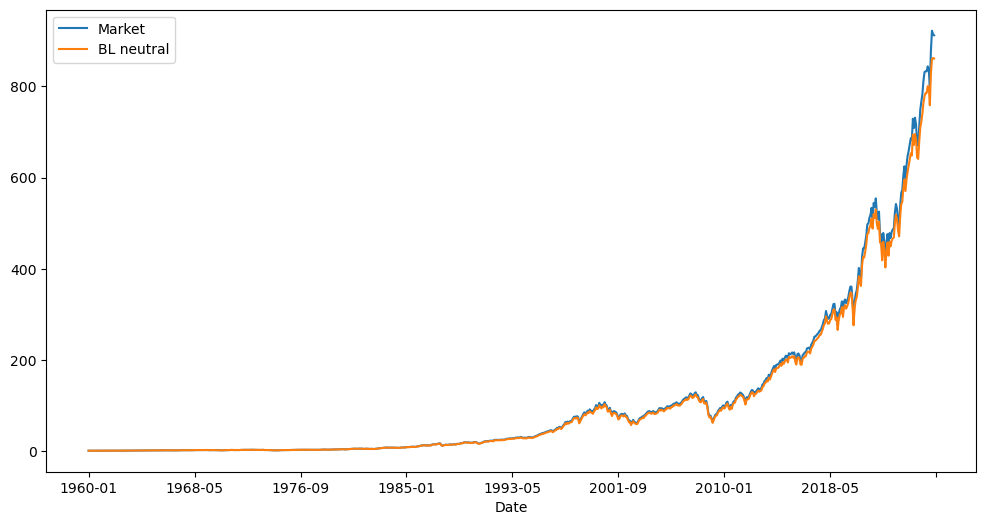

In [93]:
(btr+1).cumprod().plot(figsize = (12,6))

### Neutral BL Backtest

So... the neutral Black–Litterman portfolio closely tracks the market-cap benchmark over the full out-of-sample period.

This is well expected because the views are set equal to the market-implied equilibrium returns. Small deviations arise from the effective Black–Litterman covariance matrix and portfolio constraints (implemented within optimal weights procedure).

In [94]:
pt.summary_stats(btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
Market,0.107783,0.152765,-0.464296,4.664148,0.067104,0.095400,0.556104,-0.500086
BL neutral,0.106828,0.152603,-0.473251,4.689696,0.067179,0.095884,0.550857,-0.502129


### Historical-View Backtest

The Black–Litterman strategy is now backtested using trailing 60-month average excess returns as historical views.

```python
def historical_views(r, pi, rf, **kwargs):

    rf_window = rf.loc[r.index]

    excess_rets = r.sub(rf_window, axis=0)

    q = excess_rets.mean() * 12

    return q
```
Remember: 
- $\Pi$, $Q$, and $\mu_{BL}$ are expected **excess returns**.
- Backtested BL portfolio returns are realized **total returns**.
- The risk-free rate is subtracted later when computing the Sharpe ratio.

BL gives expected excess returns → we derive weights → the backtest applies those weights to realized total returns from the dataset.


In [95]:
historical_bl_rets = pt.backtest_ws_a(
    rets,
    estimation_window=60,
    weighting=pt.weighting_bl,
    rebalance_every=3,
    cap_weights=weights,
    view_func=pt.historical_views,
    rf=rf
)

<Axes: xlabel='Date'>

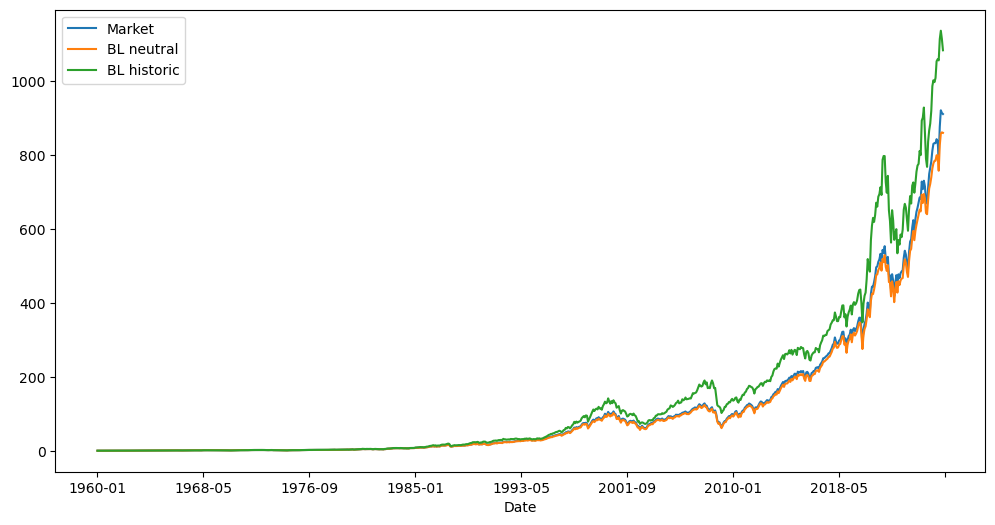

In [96]:
btr = pd.DataFrame({
    'Market': ind_rets,
    'BL neutral':neutral_bl_rets,
    'BL historic':historical_bl_rets,
}).dropna()

(btr+1).cumprod().plot(figsize = (12,6))

### About the Sharpe Ratio

I came acrooss this realisation when i decide to calculate the SR using the Series of historical RF rate. I initially thought of the Sharpe ratio as:

$$
\frac{\text{annualized return} - r_f}{\text{annualized volatility}}
$$

where the annualized return was calculated geometrically.

This interpretation was conceptually missleading.

The Sharpe ratio is based on the **expected excess return**, which in a historical sample is estimated using the arithmetic mean of periodic excess returns:

$$
\widehat{SR}
=
\frac{\overline{R-R_f}}
{\sigma(R-R_f)}
$$

For monthly data, the annualized Sharpe ratio is:

thus i slighly modified SR function: 
```python
def sharpe_ratio(r, riskfree_rate, periods_per_year):
    """
    Computes the annualized Sharpe ratio.

    riskfree_rate can be:
    - scalar: annual risk-free rate
    - Series: periodic risk-free returns aligned with r
    """

    if isinstance(riskfree_rate, pd.Series):
        rf = riskfree_rate.reindex(r.index)
        excess_ret = r - rf

    else:
        rf_per_period = (1 + riskfree_rate) ** (1 / periods_per_year) - 1
        excess_ret = r - rf_per_period

    ann_excess_ret = excess_ret.mean() * periods_per_year
    ann_excess_vol = annualize_vol(excess_ret, periods_per_year)

    return ann_excess_ret / ann_excess_vol



In [97]:
rf_btr= rf.copy()
rf_btr = rf_btr.reindex(btr.index)
rf_btr

Date
1960-01    0.0033
1960-02    0.0029
1960-03    0.0035
1960-04    0.0019
1960-05    0.0027
            ...  
2026-03    0.0029
2026-04    0.0029
2026-05    0.0031
2026-06    0.0029
2026-07    0.0033
Name: RF, Length: 799, dtype: float64

In [98]:
pt.summary_stats(btr,rf_btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
Market,0.107783,0.152765,-0.464296,4.664148,0.067104,0.095400,0.469677,-0.500086
BL neutral,0.106828,0.152603,-0.473251,4.689696,0.067179,0.095884,0.464314,-0.502129
BL historic,0.110669,0.161835,-0.431209,5.038387,0.070550,0.102565,0.469070,-0.485934


## Initial Historical-View Result

***The historical-mean estimator may indirectly capture some persistent return continuation, but it is not designed as a momentum signal.***

Historical mean view: “What return has this industry delivered on average over the last 5 years?”

The historical-view Black–Litterman strategy generates a higher annualized return than the market benchmark, but it also exhibits higher risk, so in SR there is no real change. 

_________________________________________________________________________________________________________________
_________________________________________________________________________________________________________________
## Momentum Views

The second systematic view-generation method is based on cross-sectional momentum.

The idea is that industries which have performed strongly relative to others in the recent past are assumed to continue to outperform in the near future.

For each industry, the raw momentum signal is decided to be calculated using returns from months $t-12$ to $t-2$, excluding the most recent month (12-1 signal):

$$
M_{i,t}
=\prod_{k=2}^{12}(1+r_{i,t-k}) - 1
$$

The most recent month is excluded in order to reduce the influence of short-term reversal effects.

### Cross-Sectional Standardization

The raw momentum signal is converted into a cross-sectional standardized score:

$$
z_{i,t}
=
\frac{M_{i,t}-\bar M_t}
{s(M_t)}
$$

where $\bar M_t$ is the average momentum across the 12 industries and $s(M_t)$ is the cross-sectional standard deviation.

A positive $z_{i,t}$ identifies a recent winner, while a negative value identifies a recent loser.

### How to transfer our ranking into Expected Returns Views ?

I decided to use regression to build this logic of connecting our ranking with views presented. It is estimated from historical data using a regression of future excess returns on past momentum scores:

$$
R^{excess}_{i,t+12}
=
a + b z_{i,t} + \varepsilon_{i,t}
$$

where $z_{i,t}$ is the standardized momentum signal observed at time $t$.

The estimated coefficients are then used to generate the momentum-based view:

$$
Q_{i,t}
=
\hat a_t + \hat b_t z_{i,t}
$$

***Only information available at time $t$ is used when estimating $\hat a_t$ and $\hat b_t$.***

_____________________________________________________________________________________
### Expanding Historical Calibration

At each rebalance date, the relationship between momentum and subsequent returns is estimated using an expanding historical sample.

For each historical signal date $s$:

$$
z_{i,s}
\rightarrow
R^{excess}_{i,s+12}
$$

The regression is then estimated using all available past signal-return pairs:

$$
R^{excess}_{i,s+12}
=
a_t + b_t z_{i,s} + \varepsilon_{i,s}
$$

The resulting coefficients $\hat a_t$ and $\hat b_t$ are used to convert the current momentum score into the view vector $Q_t$.

#### The question is whether this regression is pooled across all 12 industries or estimated separately for each industry (unique "a" and "b" for each industry) ?

I will go with simplification ***"momentum has roughly the same predictive effect across industries.*** For this research, it is a useful one because it gives us far more observations and avoids estimating 12 noisy separate models.
```python

momentum_raw_hist = (
    (1 + full_rets.shift(1))
    .rolling(11)
    .apply(np.prod)
    - 1
)

momentum_z_hist = momentum_raw_hist.sub(
    momentum_raw_hist.mean(axis=1),
    axis=0
).div(
    momentum_raw_hist.std(axis=1),
    axis=0
)
current_date = r.index[-1]
## r is the current rolling estimation window 
z_current = momentum_z_hist.loc[current_date]

current_pos = full_rets.index.get_loc(current_date)
last_usable_signal_date = full_rets.index[current_pos - 12]

#These are the two pieces of the training dataset for the momentum regression.
z_train = momentum_z_hist.loc[:last_usable_signal_date]
y_train = forward_12m_excess.loc[:last_usable_signal_date]
```
For each historical date, we first calculate the momentum z-score of every industry. We then observe the excess return that each industry actually earned over the following 12 months.

This gives us many historical pairs of the form:

$$
\text{momentum z-score at time } t
\rightarrow
\text{realized excess return over the next 12 months}
$$

These historical observations are pooled across all industries and used to estimate the relationship between momentum strength and subsequent returns.
```python
# Dataset with realised excess rets
train = pd.DataFrame({
    "z": z_train.stack(),
    "future_excess": y_train.stack()
}).dropna()


### Testing
recall: 
```
forward_12m_excess is not some separate mysterious dataset. We created it from the realized historical returns. Its creation procedure is visable in **01_data notebook**. 

In [99]:
test_date = "2000-12"
r_test = rets.loc[:test_date].tail(60)
current_date = r_test.index[-1]

full_rets = rets

momentum_raw_hist = (
    (1 + full_rets.shift(1))
    .rolling(11)
    .apply(np.prod)
    - 1
)

momentum_z_hist = momentum_raw_hist.sub(
    momentum_raw_hist.mean(axis=1),
    axis=0
).div(
    momentum_raw_hist.std(axis=1),
    axis=0
)

current_date = r_test.index[-1]
z_current = momentum_z_hist.loc[current_date]

current_pos = full_rets.index.get_loc(current_date)
last_usable_signal_date = full_rets.index[current_pos - 12]

z_train = momentum_z_hist.loc[:last_usable_signal_date]
y_train = forward_12m_excess.loc[:last_usable_signal_date]

train = pd.DataFrame({
    "z": z_train.stack(),
    "future_excess": y_train.stack()
}).dropna()

In [100]:
current_date

'2000-12'

In [101]:
last_usable_signal_date

'1999-12'

In [102]:
z_current

NoDur    0.721763
Durbl   -0.610495
Manuf   -0.145039
Enrgy    0.623842
Chems   -0.622049
BusEq   -1.253126
Telcm   -1.459506
Utils    1.737786
Shops   -0.562278
Hlth     1.315095
Money    0.632433
Other   -0.378427
Name: 2000-12, dtype: float64

In [103]:
train.loc['1956-01']

,z,future_excess
BusEq,-0.604239,0.118343
Chems,1.375144,-0.068823
Durbl,1.807363,-0.025241
Enrgy,0.625178,0.131724
Hlth,0.305861,0.183510
Manuf,0.958740,0.119063
Money,-1.103038,0.027072
NoDur,-0.916002,-0.012701
Other,-0.480223,-0.006592
Shops,-0.081627,-0.086669


In [104]:
import statsmodels.api as sm

X = sm.add_constant(train["z"])
y = train["future_excess"]

model = sm.OLS(y, X).fit()

#### or alternatively - as I did so before, we define intercept as a constant regressor:
```python
X = pd.DataFrame({
    "intercept": 1,
    "z": train['z']
})
y = train['future_excess']
model = sm.OLS(y,X).fit()

In [105]:
model.params

const    0.079689
z        0.014690
dtype: float64

In [106]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          future_excess   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                     31.14
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           2.50e-08
Time:                        15:30:28   Log-Likelihood:                 1185.1
No. Observations:                6348   AIC:                            -2366.
Df Residuals:                    6346   BIC:                            -2353.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0797      0.003     31.620      0.000       0.075       0.085
z              0.0147      0.003      5.581      0.000       0.010       0.020
==============================================================================
Omnibus:                      103.633   Durbin-Watson:                   0.802
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              128.412
Skew:                           0.239   Prob(JB):                     1.31e-28
Kurtosis:                       3.507   Cond. No.                         1.04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The estimated momentum-return relationship is:

$$
\widehat{R}^{excess}_{future}
=0.0797+0.0147z
$$

This implies that an industry with an average momentum score, $z=0$, is associated with an expected 12-month excess return of approximately 7.97%.

A one-standard-deviation increase in the momentum score is associated with an additional 1.47 percentage points of expected excess return.

In [107]:
a_hat = model.params["const"]
b_hat = model.params["z"]

q_current = a_hat + b_hat * z_current

In [108]:
pd.DataFrame({
    "Momentum z": z_current,
    "Q Momentum": q_current
}).sort_values("Momentum z", ascending=False)

,Momentum z,Q Momentum
Utils,1.737786,0.105216
Hlth,1.315095,0.099007
NoDur,0.721763,0.090291
Money,0.632433,0.088979
Enrgy,0.623842,0.088853
Manuf,-0.145039,0.077558
Other,-0.378427,0.074130
Shops,-0.562278,0.071429
Durbl,-0.610495,0.070721
Chems,-0.622049,0.070551


***The momentum regression has a very low $R^2$, indicating that momentum explains only a small fraction of the variation in future industry returns.***

That is obvious as expected returns are not defined merely by recent momentum. 

This is not unexpected given the high level of noise in return prediction. The more relevant question for this research is whether the resulting views improve portfolio decisions within the Black–Litterman framework. It might be the case - we will proceed ...
```
I think, that might nicely connect to our H2: forecast quality and portfolio quality are not necessarily the same thing.

### Stage 2 Extensions for the Momentum Model

It is worth mentioning that baseline momentum specification deliberately remains simple. In a stage 2, several extensions can be tested to examine whether the predictive signal can be improved without overfitting.

**Potential extensions include:**

- comparing alternative momentum horizons, such as 6-month and 12–1 momentum;
- volatility-scaling the momentum signal so that strong returns in low-volatility industries receive more weight than equally large returns in high-volatility industries;
- testing nonlinear relationships between momentum and future returns.
- replacing the linear mapping with momentum buckets or winner–loser quantiles (Maybe only the strongest winners and losers matter, while the middle is mostly noise.);
- combining momentum with additional predictors in a broader multifactor forecasting model.


so, for now simplified view function will look like that:

```python

def momentum_views(r, pi, full_rets, forward_12m_excess, **kwargs):

    current_date = r.index[-1]

    momentum_raw = (1 + full_rets.shift(1)).rolling(11).apply(np.prod) - 1

    momentum_z = momentum_raw.sub(momentum_raw.mean(axis=1), axis=0).div(momentum_raw.std(axis=1), axis=0)

    z_current = momentum_z.loc[current_date]

    current_pos = full_rets.index.get_loc(current_date)
    last_usable_date = full_rets.index[current_pos - 12]

    train = pd.DataFrame({
        "z": momentum_z.loc[:last_usable_date].stack(),
        "future_excess": forward_12m_excess.loc[:last_usable_date].stack()
    }).dropna()

    X = sm.add_constant(train["z"])
    model = sm.OLS(train["future_excess"], X).fit()

    return model.params["const"] + model.params["z"] * z_current

In [109]:
r_test = rets.loc[:"2000-12"].tail(60)

q_test = pt.momentum_views(
    r=r_test,
    pi=None,
    full_rets=rets,
    forward_12m_excess=forward_12m_excess
)

q_test

NoDur    0.090291
Durbl    0.070721
Manuf    0.077558
Enrgy    0.088853
Chems    0.070551
BusEq    0.061281
Telcm    0.058249
Utils    0.105216
Shops    0.071429
Hlth     0.099007
Money    0.088979
Other    0.074130
Name: 2000-12, dtype: float64

In [110]:
momentum_bl_rets = pt.backtest_ws_a(
    rets,
    estimation_window=60,
    weighting=pt.weighting_bl,
    rebalance_every=3,
    cap_weights=weights,
    view_func=pt.momentum_views,
    full_rets=rets,
    forward_12m_excess=forward_12m_excess
)

In [111]:
btr = pd.DataFrame({
    "Market": ind_rets,
    "BL neutral": neutral_bl_rets,
    "BL historic": historical_bl_rets,
    "BL momentum": momentum_bl_rets
}).dropna()
btr

,Market,BL neutral,BL historic,BL momentum
Date,,,,
1960-01,-0.067,-0.066221,-0.088291,-0.089852
1960-02,0.014,0.013944,0.010025,0.010124
1960-03,-0.013,-0.013390,-0.008265,-0.005399
1960-04,-0.016,-0.015722,-0.002419,-0.006516
1960-05,0.032,0.031669,0.075714,0.056062
...,...,...,...,...
2026-03,-0.049,-0.051308,-0.002921,-0.055458
2026-04,0.102,0.091282,0.054504,0.075375
2026-05,0.051,0.038029,0.020359,0.044169


In [112]:
pt.summary_stats(btr, rf_btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
Market,0.107783,0.152765,-0.464296,4.664148,0.067104,0.095400,0.469677,-0.500086
BL neutral,0.106828,0.152603,-0.473251,4.689696,0.067179,0.095884,0.464314,-0.502129
BL historic,0.110669,0.161835,-0.431209,5.038387,0.070550,0.102565,0.469070,-0.485934
BL momentum,0.118700,0.151070,-0.616128,5.294456,0.066639,0.096203,0.539127,-0.504560


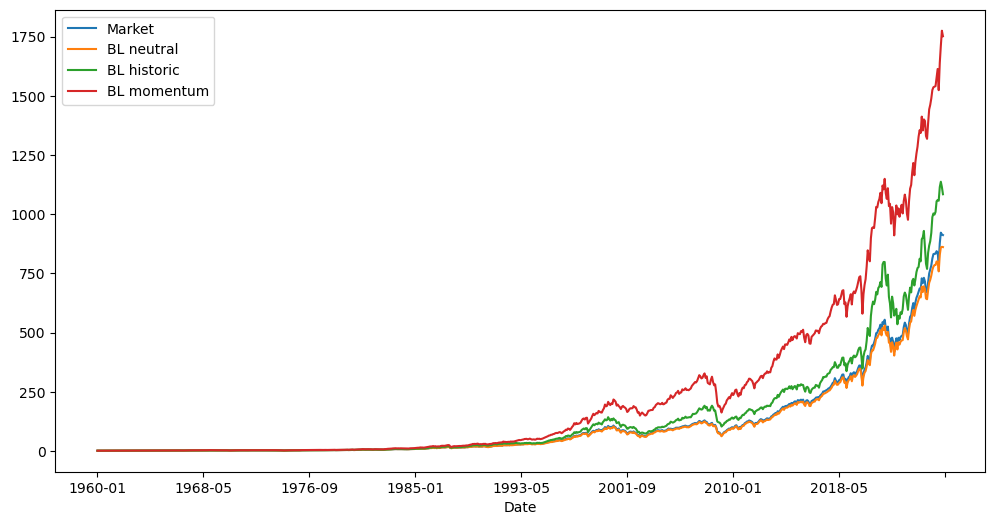

In [113]:
ax = (btr + 1).cumprod().plot(figsize=(12, 6))

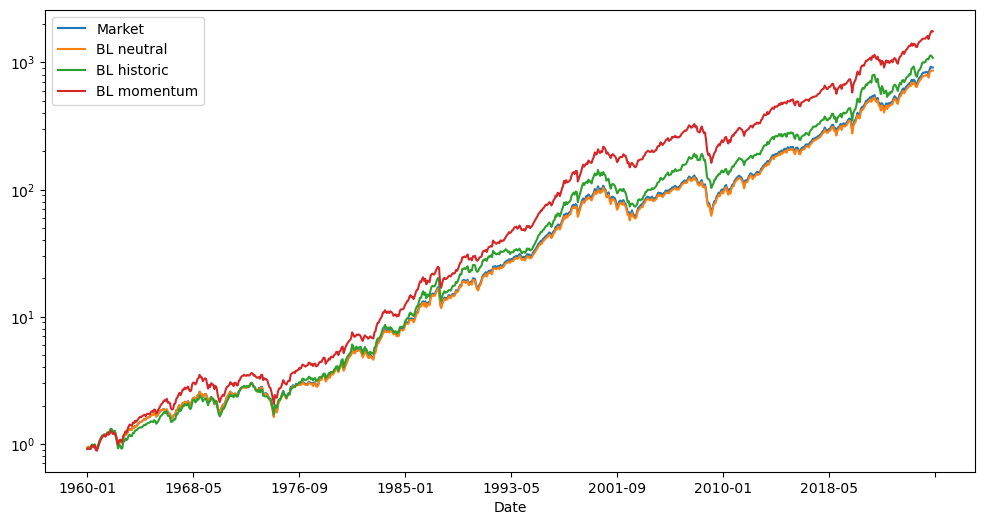

In [114]:
ax = (btr + 1).cumprod().plot(figsize=(12, 6))
ax.set_yscale("log")

### Initial Momentum-View Result

At first galnce, the momentum-based BL strategy shows a meaningful improvement over the market benchmark.

$$
SR_{Momentum} \approx 0.54
\qquad \text{vs.} \qquad
SR_{Market} \approx 0.47
$$

Unlike the historical-mean strategy, the improvement therefore does not appear to result simply from taking additional risk.

In [115]:
Path("../data/results").mkdir(parents=True, exist_ok=True)

btr.to_csv("../data/results/preliminary_results_stage1.csv")

### What if we used regression for each industry specifically ?
Tiny R2 made me think of trying to use a different approach right after, I would not stack all industries together into one regression. Instead, we will estimate unique coefficients for each industry.

We would slightly change the view function to account for that:
```python

def momentum_views_v2(r, pi, full_rets, forward_12m_excess, **kwargs):

    current_date = r.index[-1]

    momentum_raw = (1 + full_rets.shift(1)).rolling(11).apply(np.prod) - 1

    momentum_z = momentum_raw.sub(momentum_raw.mean(axis=1), axis=0).div(momentum_raw.std(axis=1), axis=0)

    z_current = momentum_z.loc[current_date]

    current_pos = full_rets.index.get_loc(current_date)
    last_usable_date = full_rets.index[current_pos - 12]


    q = pd.Series(dtype = float)
    
    for ind in momentum_z.columns:

        train_ind = pd.DataFrame({
        "z": momentum_z.loc[:last_usable_date, ind],
        "future_excess": forward_12m_excess.loc[:last_usable_date, ind]
    }).dropna()
        
        X = sm.add_constant(train_ind["z"])
        y = train_ind["future_excess"]

        model = sm.OLS(y, X).fit()

        q[ind] = (
            model.params["const"]
            + model.params["z"] * z_current[ind]
        )

    return q



In [116]:
r_test = rets.loc[:"2000-12"].tail(60)

q_test = pt.momentum_views_v2(
    r=r_test,
    pi=None,
    full_rets=rets,
    forward_12m_excess=forward_12m_excess
)

q_test

NoDur    0.145216
Durbl    0.057780
Manuf    0.064062
Enrgy    0.062605
Chems    0.050291
BusEq    0.073452
Telcm    0.065441
Utils    0.100077
Shops    0.088790
Hlth     0.160016
Money    0.096111
Other    0.064920
dtype: float64

In [117]:
momentum_v2_bl_rets = pt.backtest_ws_a(
    rets,
    estimation_window=60,
    weighting=pt.weighting_bl,
    rebalance_every=3,
    cap_weights=weights,
    view_func=pt.momentum_views_v2,
    full_rets=rets,
    forward_12m_excess=forward_12m_excess
)

In [118]:
btr_momentum = pd.DataFrame({
    "Market": ind_rets,
    "BL momentum": momentum_bl_rets,
    "BL momentum v2": momentum_v2_bl_rets
}).dropna()
btr_momentum

,Market,BL momentum,BL momentum v2
Date,,,
1960-01,-0.067,-0.089852,-0.063877
1960-02,0.014,0.010124,0.028308
1960-03,-0.013,-0.005399,0.004916
1960-04,-0.016,-0.006516,-0.006219
1960-05,0.032,0.056062,0.035705
...,...,...,...
2026-03,-0.049,-0.055458,-0.045330
2026-04,0.102,0.075375,0.071589
2026-05,0.051,0.044169,0.034322


<Axes: xlabel='Date'>

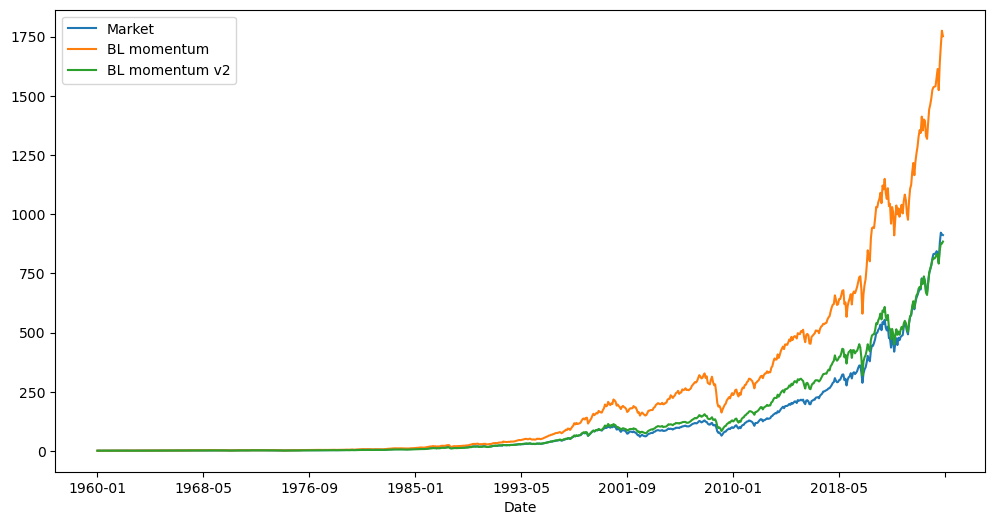

In [119]:
(btr_momentum+1).cumprod().plot(figsize = (12,6))

In [120]:
pt.summary_stats(btr_momentum)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
Market,0.107783,0.152765,-0.464296,4.664148,0.067104,0.095400,0.556104,-0.500086
BL momentum,0.118700,0.151070,-0.616128,5.294456,0.066639,0.096203,0.626422,-0.504560
BL momentum v2,0.107274,0.154112,-0.547137,5.170256,0.068321,0.097698,0.549829,-0.474112


### Industry-Specific Momentum Regression
Estimating a separate regression for each industry did not improve portfolio performance. The likely reason is that each model uses a much smaller estimation sample, making the coefficients noisier

_________________________________________________________________________________________________________________
_________________________________________________________________________________________________________________
## Factor-Based Views (check the section "Reconsidered 1&2" )

The third systematic view-generation method uses a factor model.

Industry excess returns are modeled as exposures to common systematic factors:

$$
R^{excess}_{i,t}
=\alpha_i+\beta_{i,MKT}MKT_t+\beta_{i,SMB}SMB_t+\beta_{i,HML}HML_t+\varepsilon_{i,t}
$$

At each rebalance date, factor exposures are estimated from historical data and are used to generate the Black–Litterman view vector $Q_t$.

In [121]:
ff_factors = dt.get_fff_returns()[rets.index[0]:]
ff_factors

,Mkt-RF,SMB,HML,RF
Date,,,,
1955-01,0.0060,0.0024,0.0210,0.0008
1955-02,0.0302,0.0155,0.0061,0.0009
1955-03,-0.0015,-0.0065,0.0193,0.0010
1955-04,0.0311,-0.0175,0.0075,0.0010
1955-05,0.0094,-0.0025,-0.0096,0.0014
...,...,...,...,...
2026-03,-0.0518,0.0044,0.0329,0.0029
2026-04,0.0995,0.0019,-0.0137,0.0029
2026-05,0.0491,-0.0159,-0.0231,0.0031


### Testing on a specific industry with specific dates 

In [122]:
ff_factors.index = ff_factors.index.astype(str)

In [123]:
test_date = "2000-12"

r_window = rets.loc[:test_date].tail(60)
f_window = ff_factors.loc[r_window.index, ["Mkt-RF", "SMB", "HML"]]
rf_window = ff_factors.loc[r_window.index, "RF"]

y = r_window["NoDur"] - rf_window
X = sm.add_constant(f_window)


In [124]:
model = sm.OLS(y, X).fit()
model.summary() , model.params

(<class 'statsmodels.iolib.summary.Summary'>
 """
                             OLS Regression Results                            
 Dep. Variable:                      y   R-squared:                       0.599
 Model:                            OLS   Adj. R-squared:                  0.577
 Method:                 Least Squares   F-statistic:                     27.86
 Date:                Fri, 23 Oct 2026   Prob (F-statistic):           3.72e-11
 Time:                        15:32:03   Log-Likelihood:                 127.13
 No. Observations:                  60   AIC:                            -246.3
 Df Residuals:                      56   BIC:                            -237.9
 Df Model:                           3                                         
 Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
 ---------------------------------------------------------------------

So, objective - we are systematically tilting our BL views toward industries exposed to factors that currently have higher estimated expected returns.
### Pay attention to the ***significance of SMB !*** (CHECK "RECONSIDERED 2")
we will talk about this ***later*** and maybe conclude the lack of reasonability for using this factor for views implementation, at least while we work with KF dataset of 12 industries which themselves are value - weighted.

In [125]:
factor_premia = f_window.mean() * 12
factor_premia

Mkt-RF    0.12136
SMB      -0.03948
HML       0.05038
dtype: float64

The Black–Litterman view for industry $i$ is then constructed as:

$$
Q_i
=
12\hat{\alpha}_i
+
\hat{\beta}_{i,MKT}E[MKT]
+
\hat{\beta}_{i,SMB}E[SMB]
+
\hat{\beta}_{i,HML}E[HML]
$$

For now: statistical significance of the regression coefficients is not used as a filtering rule in the baseline model.

In [126]:
q_nodur = (
    model.params["const"] * 12
    + model.params["Mkt-RF"] * factor_premia["Mkt-RF"]
    + model.params["SMB"] * factor_premia["SMB"]
    + model.params["HML"] * factor_premia["HML"]
)

q_nodur

np.float64(0.08667999999999992)

### Now we test factor views on all indutries for a specific date:

In [127]:
q_factor = pd.Series(index=rets.columns, dtype=float)
exposures = pd.DataFrame(
    index=rets.columns,
    columns=["Alpha", "Mkt-RF", "SMB", "HML"],
    dtype=float
)
for industry in rets.columns:
    y = r_window[industry] - rf_window
    X = sm.add_constant(f_window)

    model = sm.OLS(y, X).fit()
    exposures.loc[industry] = [
        model.params["const"],
        model.params["Mkt-RF"],
        model.params["SMB"],
        model.params["HML"]
    ]
    q_factor[industry] = (
        model.params["const"] * 12
        + model.params["Mkt-RF"] * factor_premia["Mkt-RF"]
        + model.params["SMB"] * factor_premia["SMB"]
        + model.params["HML"] * factor_premia["HML"]
    )

exposures['Views %']= (q_factor*100)
exposures["Alpha"] = exposures["Alpha"] * 12

In [128]:
exposures.round(3).sort_values(by = 'Views %',ascending=False)

,Alpha,Mkt-RF,SMB,HML,Views %
BusEq,0.140,1.094,-0.017,-1.114,21.716
Hlth,0.109,0.572,-0.162,-0.073,18.154
Money,-0.047,1.377,-0.219,0.868,17.210
Enrgy,0.001,0.801,0.094,0.633,12.654
Shops,-0.012,0.971,-0.063,0.349,12.582
Manuf,-0.031,1.097,-0.036,0.350,12.078
Utils,0.006,0.433,0.045,0.766,9.524
NoDur,-0.055,0.864,-0.016,0.725,8.668
Telcm,-0.012,0.808,-0.231,-0.350,7.780
Chems,-0.064,0.867,-0.063,0.583,7.342


So, now we build a reusable function for factor-based views and backtest it:

```python
def factor_views(r, pi, ff_factors, **kwargs):
    """
    Generates Black–Litterman views from a Fama–French 3-factor model.
    """

    factors = ff_factors.loc[r.index, ["Mkt-RF", "SMB", "HML"]]
    rf = ff_factors.loc[r.index, "RF"]

    factor_premia = factors.mean() * 12

    q = pd.Series(index=r.columns, dtype=float)

    X = sm.add_constant(factors)

    for industry in r.columns:
        y = r[industry] - rf
        model = sm.OLS(y, X).fit()

        q[industry] = (
            ### model.params["const"] * 12 - that will be removed in a tollkit.
            + model.params["Mkt-RF"] * factor_premia["Mkt-RF"]
            + model.params["SMB"] * factor_premia["SMB"]
            + model.params["HML"] * factor_premia["HML"]
        )

    return q

In [129]:
q_test_factor = pt.factor_views(
    r=r_window,
    pi=None,
    ff_factors=ff_factors
)

q_test_factor.sort_values(ascending = False)

Money    0.219464
Durbl    0.164219
Manuf    0.152250
NoDur    0.141994
Other    0.138001
Shops    0.137919
Chems    0.137025
Enrgy    0.125345
Telcm    0.089571
Utils    0.089399
BusEq    0.077358
Hlth     0.072144
dtype: float64

In [130]:
factor_bl_rets = pt.backtest_ws_a(
    rets,
    estimation_window=60,
    weighting=pt.weighting_bl,
    rebalance_every=3,
    cap_weights=weights,
    view_func=pt.factor_views,
    ff_factors=ff_factors
)

In [131]:
btr = pd.DataFrame({
    "Market": ind_rets,
    "BL neutral": neutral_bl_rets,
    "BL historic": historical_bl_rets,
    "BL momentum": momentum_bl_rets,
    "BL factor": factor_bl_rets
}).dropna()
btr

,Market,BL neutral,BL historic,BL momentum,BL factor
Date,,,,,
1960-01,-0.067,-0.066221,-0.088291,-0.089852,-0.078637
1960-02,0.014,0.013944,0.010025,0.010124,0.012187
1960-03,-0.013,-0.013390,-0.008265,-0.005399,-0.018687
1960-04,-0.016,-0.015722,-0.002419,-0.006516,-0.017586
1960-05,0.032,0.031669,0.075714,0.056062,0.039808
...,...,...,...,...,...
2026-03,-0.049,-0.051308,-0.002921,-0.055458,-0.023749
2026-04,0.102,0.091282,0.054504,0.075375,0.026252
2026-05,0.051,0.038029,0.020359,0.044169,-0.011453


In [132]:
pt.summary_stats(btr, rf_btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
Market,0.107783,0.152765,-0.464296,4.664148,0.067104,0.095400,0.469677,-0.500086
BL neutral,0.106828,0.152603,-0.473251,4.689696,0.067179,0.095884,0.464314,-0.502129
BL historic,0.110669,0.161835,-0.431209,5.038387,0.070550,0.102565,0.469070,-0.485934
BL momentum,0.118700,0.151070,-0.616128,5.294456,0.066639,0.096203,0.539127,-0.504560
BL factor,0.114011,0.155220,-0.555790,5.584255,0.068084,0.099953,0.501634,-0.557171


<Axes: xlabel='Date'>

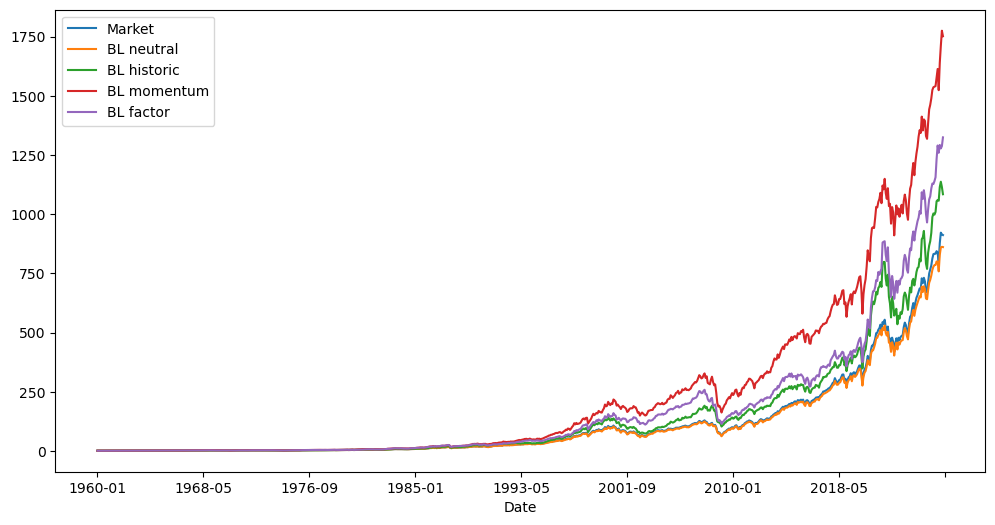

In [133]:
(btr+1).cumprod().plot(figsize = (12,6))

### Some may ask about the constant regressor term: where did it go ? 

I got to notice when I attemted to make a first version of this function: the factor model would be mathematically collapsing into the historical-return model...

Once alpha is included (in the view generation process), the factor-based expected return is simply reconstructing the historical average excess return. So the model is not generating a genuinely new source of views at all, let us remove it from the view construction.

So, the function does not include alpha for the view generation...

# Reconsidered
### Factor-Based Views: Experimental ALternative
#### The factor model interpreted as a source of systematic deviations from the Black–Litterman equilibrium prior. 

We would like to see whether factor information works better as a relative adjustment around the equilibrium prior.

The revised structure is:

$$
Q_{i,t}
=
\Pi_{i,t}
+
\text{Factor Tilt}_{i,t},
$$

The factor tilt is based only on non-market style exposures ! 

The market factor is still included in the regression when estimating the betas, as it is deemed as a separate factor, but its expected return is not added separately to the view. 

Expected SMB and HML premia are estimated using an **expanding historical window** available at each rebalance date, while factor exposures are estimated using the old way. 

**AGAIN, WE WILL TALK ABOUT SMB LATER** (RECONSIDERED 2)

Rather than using raw factor-implied returns directly, the factor signal is converted into a simple cross-sectional attractiveness measure.
Both adjusted view function and factor score data function are presented below:

```python
def factor_views_adjusted(r,pi,factor_score_hist, forward_12m_excess,**kwargs):
    """
    Generates BL views from historically calibrated factor scores.
    """

    current_date = r.index[-1]

    z_current = factor_score_hist.loc[current_date]

    current_pos = factor_score_hist.index.get_loc(current_date)
    last_usable_date = factor_score_hist.index[current_pos - 12]

    z_train = factor_score_hist.loc[:last_usable_date]
    y_train = forward_12m_excess.loc[:last_usable_date]

    train = pd.DataFrame({
        "z": z_train.stack(),
        "future_excess": y_train.stack()
    }).dropna()

    X = sm.add_constant(train["z"])
    model = sm.OLS(train["future_excess"], X).fit()

    return pi + model.params["z"] * z_current

def compute_factor_score_history(full_rets, ff_factors, window=60):
    """
    Precomputes cross-sectional SMB/HML factor scores for all dates.
    """

    factor_score_hist = pd.DataFrame(
        index=full_rets.index,
        columns=full_rets.columns,
        dtype=float
    )

    for end in range(window - 1, len(full_rets)):
        current_date = full_rets.index[end]

        r_window = full_rets.iloc[end-window+1:end+1]

        factors_window = ff_factors.loc[
            r_window.index,
            ["Mkt-RF", "SMB", "HML"]
        ]

        rf_window = ff_factors.loc[r_window.index, "RF"]

        factor_premia = (
            ff_factors.loc[:current_date, ["SMB", "HML"]]
            .mean()
            * 12
        )

        X = sm.add_constant(factors_window)

        scores = pd.Series(index=full_rets.columns, dtype=float)

        for industry in full_rets.columns:
            y = r_window[industry] - rf_window

            model = sm.OLS(y, X).fit()

            scores[industry] = (
                model.params["SMB"] * factor_premia["SMB"]
                + model.params["HML"] * factor_premia["HML"]
            )

        factor_score_hist.loc[current_date] = (
            scores - scores.mean()
        ) / scores.std()

    return factor_score_hist
```

For each industry $i$, define the factor score (check **def compute_factor_score_history**):

$$
S_{i,t}
=
\hat{\beta}_{i,SMB,t}E_t[SMB]
+
\hat{\beta}_{i,HML,t}E_t[HML].
$$

The average factor score across the 12 industries is then:

$$
\bar S_t
=
\frac{1}{12}\sum_{i=1}^{12} S_{i,t}.
$$

A cross-sectional z-score is calculated as:

$$
z_{i,t}
=
\frac{S_{i,t}-\bar S_t}{s(S_t)}.
$$

The purpose of this transformation is mainly **ranking and normalization**. It simply indicates how attractive an industry's factor exposure is relative to the other industries.

Thus, a positive z-score means above-average factor attractiveness, while a negative z-score means below-average attractiveness.

In [134]:
full_rets = dt.get_ind_returns(n_inds=12, weighting="vw")
full_rets.index = full_rets.index.astype(str)
ff_factors_full = dt.get_fff_returns()
ff_factors_full.index = ff_factors_full.index.astype(str)

In [135]:
factor_score_hist = pt.compute_factor_score_history(
    full_rets=full_rets,
    ff_factors=ff_factors_full,
    window=60
)

In [136]:
factor_adjusted_bl_rets = pt.backtest_ws_a(
    rets,
    estimation_window=60,
    weighting=pt.weighting_bl,
    rebalance_every=3,
    cap_weights=weights,
    view_func=pt.factor_views_adjusted,
    factor_score_hist=factor_score_hist,
    forward_12m_excess=forward_12m_excess
)

In [137]:
btr = pd.DataFrame({
    "Market": ind_rets,
    "BL neutral": neutral_bl_rets,
    "BL historic": historical_bl_rets,
    "BL momentum": momentum_bl_rets,
    "BL factor": factor_bl_rets,
    "BL factor adjusted": factor_adjusted_bl_rets
}).dropna()

In [138]:
pt.summary_stats(btr, rf_btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
Market,0.107783,0.152765,-0.464296,4.664148,0.067104,0.095400,0.469677,-0.500086
BL neutral,0.106828,0.152603,-0.473251,4.689696,0.067179,0.095884,0.464314,-0.502129
BL historic,0.110669,0.161835,-0.431209,5.038387,0.070550,0.102565,0.469070,-0.485934
BL momentum,0.118700,0.151070,-0.616128,5.294456,0.066639,0.096203,0.539127,-0.504560
BL factor,0.114011,0.155220,-0.555790,5.584255,0.068084,0.099953,0.501634,-0.557171
BL factor adjusted,0.108914,0.155893,-0.490172,4.756414,0.068773,0.099211,0.470231,-0.536494


<Axes: xlabel='Date'>

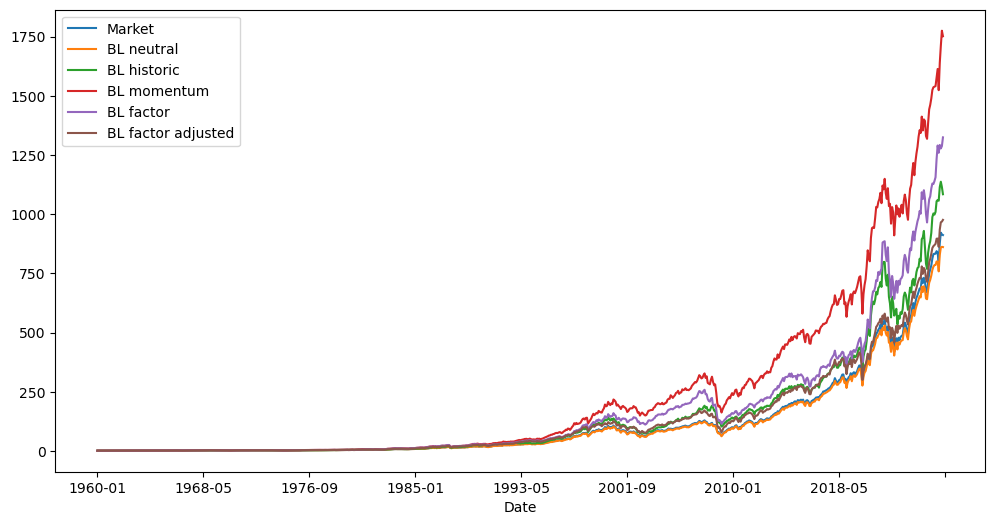

In [124]:
(btr + 1).cumprod().plot(figsize=(12, 6))

### Given the poor performance of the adjusted version we will further look at another approach.
#### I would try to simplify our factor view function and just generates BL views by tilting the prior toward industries exposed to factors with positive expected premia.
```python

def factor_views_simple(r, pi, ff_factors, **kwargs):

    current_date = r.index[-1]

    factors = ff_factors.loc[
        r.index,
        ["Mkt-RF", "SMB", "HML"]
    ]

    rf = ff_factors.loc[r.index, "RF"]

    factor_premia = (
        ff_factors.loc[:current_date, ["SMB", "HML"]]
        .mean()
        * 12
    )

    winning_premia = factor_premia.clip(lower=0)

    X = sm.add_constant(factors)

    factor_tilt = pd.Series(index=r.columns, dtype=float)

    for industry in r.columns:
        y = r[industry] - rf
        model = sm.OLS(y, X).fit()

        factor_tilt[industry] = (
            model.params["SMB"] * winning_premia["SMB"]
            + model.params["HML"] * winning_premia["HML"]
        )

    factor_tilt = factor_tilt - factor_tilt.mean()

    return pi + factor_tilt

In [139]:
factor_simple_bl_rets = pt.backtest_ws_a(
    rets,
    estimation_window=60,
    weighting=pt.weighting_bl,
    rebalance_every=3,
    cap_weights=weights,
    view_func=pt.factor_views_simple,
    ff_factors=ff_factors
)

We will compare factor - based views on a separate graph (table):

In [140]:
btr_factor = pd.DataFrame({
    "BL factor": factor_bl_rets,
    "BL factor adjusted": factor_adjusted_bl_rets
}).dropna()

btr_factor["BL factor simple"] = factor_simple_bl_rets

In [141]:
pt.summary_stats(btr_factor, rf_btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
BL factor,0.114011,0.155220,-0.555790,5.584255,0.068084,0.099953,0.501634,-0.557171
BL factor adjusted,0.108914,0.155893,-0.490172,4.756414,0.068773,0.099211,0.470231,-0.536494
BL factor simple,0.112946,0.155911,-0.479424,5.105336,0.068031,0.097393,0.493751,-0.544758


<Axes: xlabel='Date'>

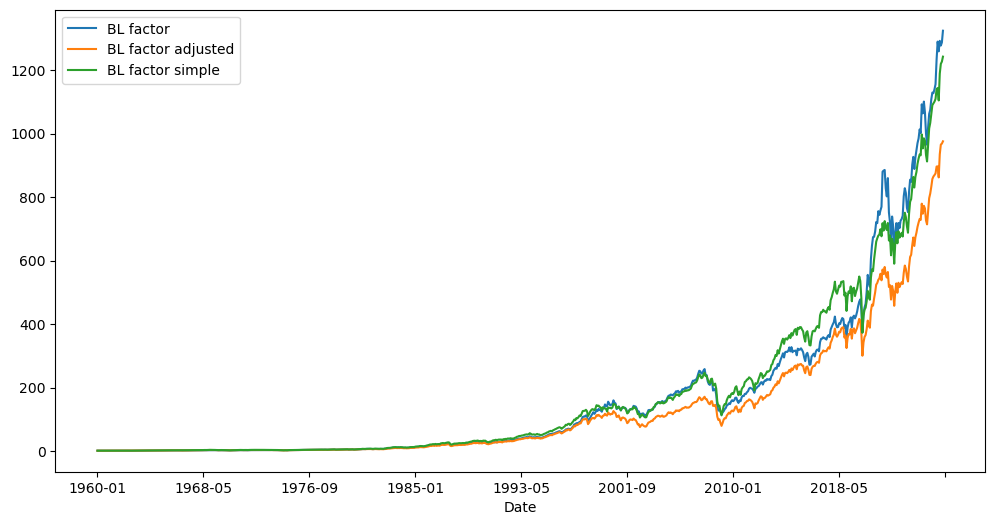

In [142]:
(btr_factor+1).cumprod().plot(figsize = (12,6))

It looks like our first factor based view function worked out best of all in a factor "story" so far...

# Reconsidered 2 
### Factor-Based Views: Removing SMB

The question is whether all Fama–French factors are equally meaningful for a universe of 12 **value-weighted** industry portfolios.

In particular, the SMB factor appears to provide relatively little cross-sectional differentiation across industries. This is INDEED very plausible because the industry portfolios themselves are value-weighted and therefore dominated by larger firms...


Given the intuitive weak explanatory power of SMB variable, it might be worth to exclude it. At least while we work with this dataset, it would meaningful to estimate our regression as:

$$
R^{excess}_{i,t}
=
\alpha_i
+
\beta_{i,MKT}MKT_t
+
\beta_{i,HML}HML_t
+
\varepsilon_{i,t}.
$$

The market factor is used to control for broad equity-market exposure, while HML provides the active factor tilt used in the Black–Litterman views.

SMB may become more relevant in **a different investment universe**, for example a broad cross-section of individual stocks such as the S&P 500 or the Russell 3000, where meaningful variation in firm size exists across securities.

Therefore, we would backtest:

```python

def factor_views_value(r, pi, ff_factors, **kwargs):
    """
    Generates BL views by tilting the prior toward industries
    with positive exposure to the value factor.
    """

    current_date = r.index[-1]

    factors = ff_factors.loc[r.index, ["Mkt-RF", "HML"]]
    rf = ff_factors.loc[r.index, "RF"]

    hml_premium = ff_factors.loc[:current_date, "HML"].mean() * 12
    hml_premium = max(hml_premium, 0)

    X = sm.add_constant(factors)

    factor_tilt = pd.Series(index=r.columns, dtype=float)

    for industry in r.columns:
        y = r[industry] - rf
        model = sm.OLS(y, X).fit()

        factor_tilt[industry] = (
            model.params["HML"] * hml_premium
        )

    factor_tilt = factor_tilt - factor_tilt.mean()

    return pi + factor_tilt

In [143]:
factor_value_bl_rets = pt.backtest_ws_a(
    rets,
    estimation_window=60,
    weighting=pt.weighting_bl,
    rebalance_every=3,
    cap_weights=weights,
    view_func=pt.factor_views_value,
    ff_factors=ff_factors
)

In [144]:
btr_factor["BL factor value"] = factor_value_bl_rets
pt.summary_stats(btr_factor, rf_btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
BL factor,0.114011,0.155220,-0.555790,5.584255,0.068084,0.099953,0.501634,-0.557171
BL factor adjusted,0.108914,0.155893,-0.490172,4.756414,0.068773,0.099211,0.470231,-0.536494
BL factor simple,0.112946,0.155911,-0.479424,5.105336,0.068031,0.097393,0.493751,-0.544758
BL factor value,0.109870,0.149101,-0.461871,4.867680,0.064950,0.093736,0.490397,-0.539694


<Axes: xlabel='Date'>

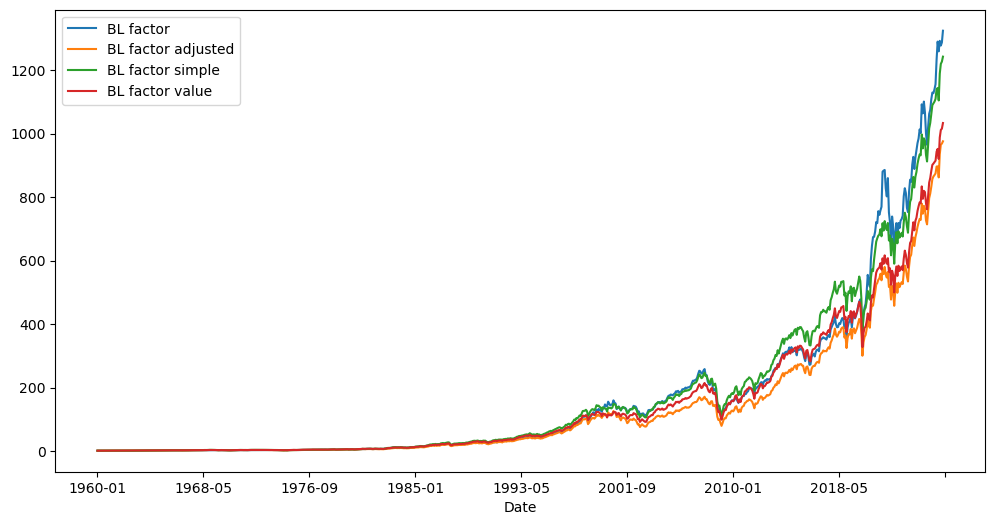

In [145]:
(btr_factor + 1).cumprod().plot(figsize=(12, 6))

### Factor-Model Takeaway

Several factor-based specifications were tested, including the original factor-implied return approach, a prior-adjusted tilt, a simplified positive-premia version, and an HML-focused value specification. The different implementations produced broadly similar results and none materially improved on the best-performing momentum specification.

For the current universe of 12 value-weighted industry portfolios, factor exposures may be too coarse or unstable to generate a particularly strong Black–Litterman view signal.

_________________________________________________________________________________________________________________
_________________________________________________________________________________________________________________
# Evaluation
## Winners Comparison

In [146]:
btr_summary = btr[
    [
        "Market",
        "BL historic",
        "BL momentum",
        "BL factor"
    ]
].dropna()
pt.summary_stats(btr_summary, rf_btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
Market,0.107783,0.152765,-0.464296,4.664148,0.067104,0.095400,0.469677,-0.500086
BL historic,0.110669,0.161835,-0.431209,5.038387,0.070550,0.102565,0.469070,-0.485934
BL momentum,0.118700,0.151070,-0.616128,5.294456,0.066639,0.096203,0.539127,-0.504560
BL factor,0.114011,0.155220,-0.555790,5.584255,0.068084,0.099953,0.501634,-0.557171


<Axes: xlabel='Date'>

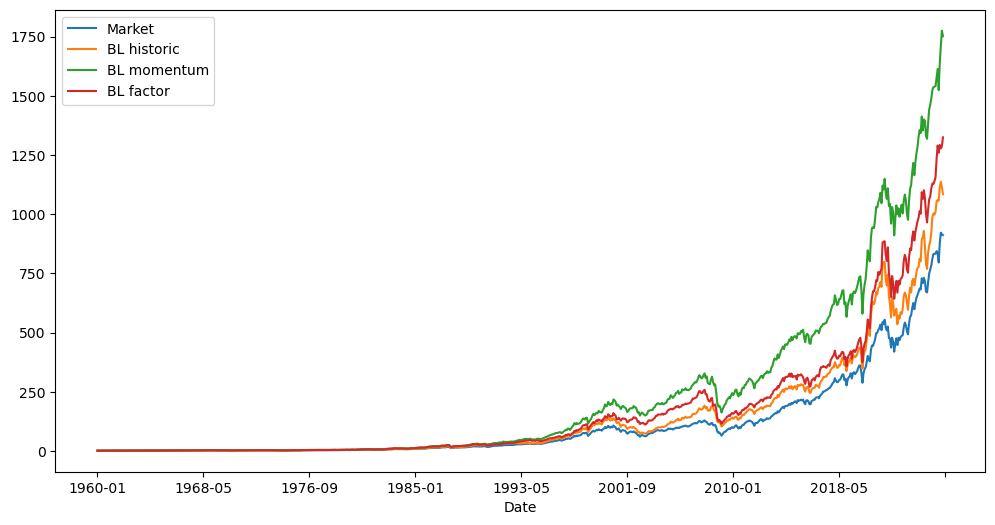

In [147]:
(btr_summary+1).cumprod().plot(figsize=(12, 6))

## Sensitivity to key inputs
Yet, the preliminary results suggest some improvement over the market benchmark. The next natural step is to test how sensitive these results are to key implementation choices, particularly the rebalancing frequency and estimation-window length.

In [148]:
windows = [36, 60, 120]
rebalances = [1, 3, 6, 12]

In [149]:
strategies = {
    "Historical": (
        pt.historical_views,
        {"rf": rf}
    ),

    "Momentum": (
        pt.momentum_views,
        {
            "full_rets": rets,
            "forward_12m_excess": forward_12m_excess
        }
    ),

    "Factor": (
        pt.factor_views,
        {"ff_factors": ff_factors}
    )
}

In [151]:
results = []

for window in windows:
    for rebalance in rebalances:

        for name, (view_func, extra_kwargs) in strategies.items():

            strategy_rets = pt.backtest_ws_a(
                rets,
                estimation_window=window,
                weighting=pt.weighting_bl,
                rebalance_every=rebalance,
                cap_weights=weights,
                view_func=view_func,
                **extra_kwargs
            )

            strategy_rets = strategy_rets.dropna()

            rf_test = rf_btr.reindex(strategy_rets.index)

            stats = pt.summary_stats(
                strategy_rets.to_frame(name),
                rf_test
            ).iloc[0]

            results.append({
                "Strategy": name,
                "Window": window,
                "Rebalance": rebalance,
                "Return": stats["Annualized Return"],
                "Vol": stats["Annualized Vol"],
                "Sharpe": stats["Sharpe Ratio"],
                "Max DD": stats["Max Drawdown"]
            })

In [152]:
robustness = pd.DataFrame(results)
robustness.head()

,Strategy,Window,Rebalance,Return,Vol,Sharpe,Max DD
0,Historical,36,1,0.117206,0.157899,0.477579,-0.478832
1,Momentum,36,1,0.128366,0.146462,0.571800,-0.454152
2,Factor,36,1,0.115948,0.148615,0.499470,-0.447344
3,Historical,36,3,0.116103,0.158201,0.470167,-0.501116
4,Momentum,36,3,0.127589,0.148371,0.564256,-0.478998


for a better representation, let us construct a pivot table:

In [161]:
pivot =robustness.pivot_table(
    index=["Window", "Rebalance"],
    columns="Strategy",
    values=["Return",'Sharpe']
).round(3)

In [159]:
styled = (
    pivot.style
    .format("{:.3f}")
    .highlight_max(axis=0,props="background-color: lightgreen; color: black")
    .set_caption("Across Estimation Windows and Rebalancing Frequencies")
)
styled

In [162]:
robust_summary = robustness.groupby("Strategy").agg(
    Mean_Sharpe=("Sharpe", "mean"),
    Min_Sharpe=("Sharpe", "min"),
    Max_Sharpe=("Sharpe", "max"),
    Std_Sharpe=("Sharpe", "std"),
    Mean_Return=("Return", "mean")
)

robust_summary

,Mean_Sharpe,Min_Sharpe,Max_Sharpe,Std_Sharpe,Mean_Return
Strategy,,,,,
Factor,0.503977,0.487338,0.527295,0.013659,0.117102
Historical,0.453242,0.426301,0.477579,0.017627,0.110592
Momentum,0.550240,0.515693,0.586025,0.020805,0.122649


## Results: Robustness Across Estimation Windows and Rebalancing Frequencies

The main objective is not to identify the single best parameter combination, but to assess whether each strategy performs consistently across different choices.

***Momentum performs best on average***, with a mean Sharpe ratio of approximately 0.55 and a minimum Sharpe ratio above 0.51 across all tested specifications.

## Forecast evaluation
Here comes an important step - evaluating how good our genereated views were. We will use standard preset: est. window = 60 months and rebalance = every 3 months.

In [163]:
historical_q = []
momentum_q = []
factor_q = []
view_dates = []

In [164]:
estimation_window = 60
rebalance_every = 3

for start in range(
    0,
    len(rets) - estimation_window + 1,
    rebalance_every
):
    end = start + estimation_window
    r_window = rets.iloc[start:end]

    current_date = r_window.index[-1]

    # Same BL prior calculation as in weighting_bl()
    sigma = pt.shrinkage_cov(r_window, delta=0.5) * 12
    w_mkt = weights.loc[current_date]
    pi = pt.implied_rets(
        delta=2.5,
        sigma=sigma,
        w=w_mkt
    )

    q_hist = pt.historical_views(
        r=r_window,
        pi=pi,
        rf=rf
    )

    q_mom = pt.momentum_views(
        r=r_window,
        pi=pi,
        full_rets=rets,
        forward_12m_excess=forward_12m_excess
    )

    q_factor = pt.factor_views(
        r=r_window,
        pi=pi,
        ff_factors=ff_factors
    )

    historical_q.append(q_hist)
    momentum_q.append(q_mom)
    factor_q.append(q_factor)
    view_dates.append(current_date)

In [165]:
historical_q = pd.DataFrame(
    historical_q,
    index=view_dates
)

momentum_q = pd.DataFrame(
    momentum_q,
    index=view_dates
)

factor_q = pd.DataFrame(
    factor_q,
    index=view_dates
)

In [166]:
historical_q.shape , forward_12m_excess['1959-12'::rebalance_every].dropna().shape

((267, 12), (263, 12))

In [172]:
ref = forward_12m_excess.loc[historical_q.index].dropna()

historical_q_eval = historical_q.loc[ref.index]
momentum_q_eval = momentum_q.loc[ref.index]
factor_q_eval = factor_q.loc[ref.index]

q_eval_1 = pd.DataFrame({
    "HIST": historical_q_eval.sub(ref).mean(axis = 1).squeeze(),
    "MMNT": momentum_q_eval.sub(ref).mean(axis = 1).squeeze(),
    "FCTR": factor_q_eval.sub(ref).mean(axis = 1).squeeze()
})

### The first chart is the average signed forecast error across the 12 industries at each date

<Axes: >

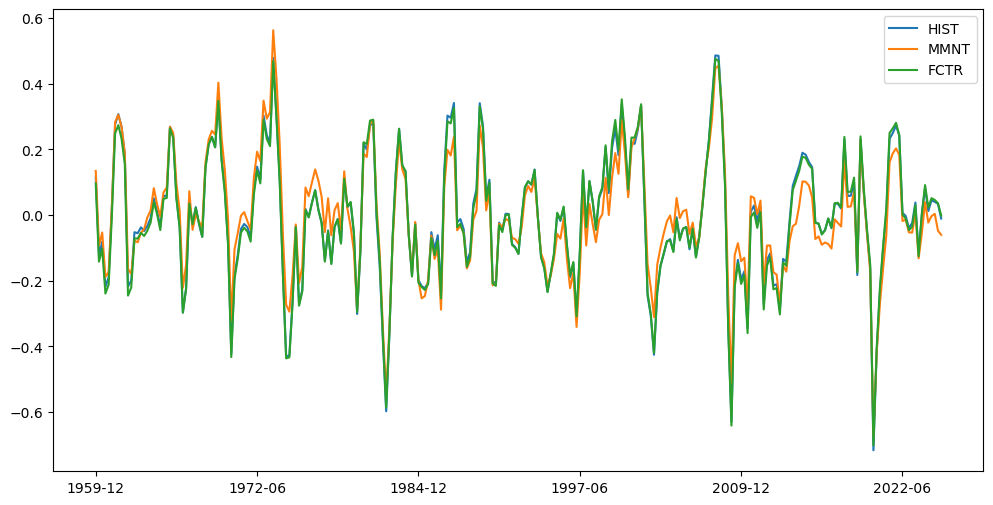

In [173]:
q_eval_1.plot(figsize = (12,6))

### This is simply for answering: Was the model on average too optimistic or too pessimistic at each date?

It does not answer:

***Which model forecasts returns better?***

<Axes: >

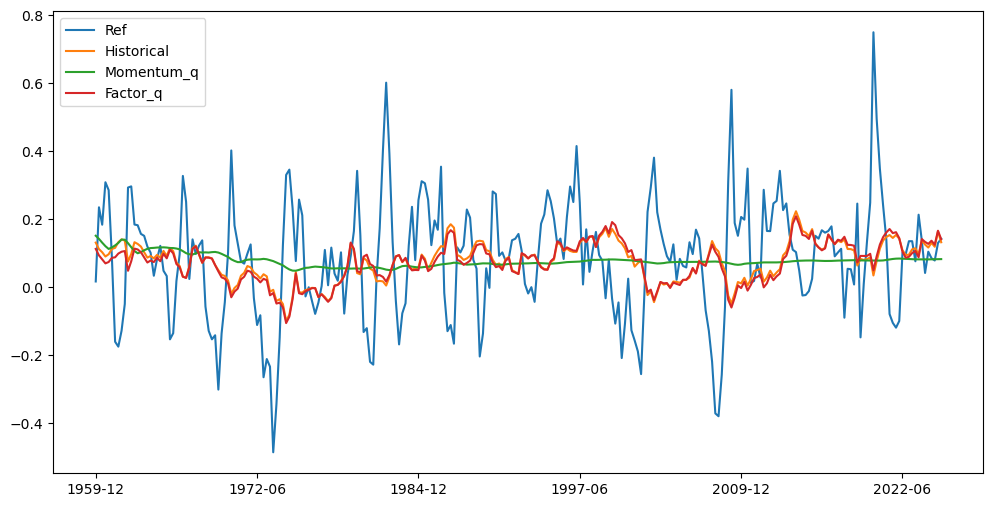

In [168]:
q_eval_2 = pd.DataFrame({
    "Ref":ref.mean(axis = 1),
    "Historical": historical_q_eval.mean(axis = 1),
    "Momentum_q":momentum_q_eval.mean(axis = 1),
    "Factor_q":factor_q_eval.mean(axis = 1)
}, index = ref.index)
q_eval_2.plot(figsize = (12,6))

### Here again...
***We see that the way our current factor view is constructed produces an average expected-return level through time that is very similar to historical views.***

### Average Predicted vs Realized 12-Month Excess Returns

The chart compares the cross-sectional average return across all 12 industries at each forecast date:

- **Ref** represents the average excess return actually realized over the following 12 months.
- **Historical, Momentum, and Factor** represent the average 12-month excess return predicted by each view-generation method.
```
That tells you the methods differ substantially in how much they let expected returns vary over time.
```
Importantly, this chart evaluates the **overall level of expected returns**, not the models' ability to rank individual industries.

In [204]:
forecast_comparison = pd.DataFrame({
    "RMSE": [
        np.sqrt(((historical_q_eval - ref)**2).stack().mean()),
        np.sqrt(((momentum_q_eval - ref)**2).stack().mean()),
        np.sqrt(((factor_q_eval - ref)**2).stack().mean())
    ],
    
    "MAE": [
        (historical_q_eval - ref).abs().stack().mean(),
        (momentum_q_eval - ref).abs().stack().mean(),
        (factor_q_eval - ref).abs().stack().mean()
    ]
}, index=[
    "Historical",
    "Momentum",
    "Factor"
])
forecast_comparison["Mean IC"] = [
    historical_q_eval.corrwith(ref, axis=1,method="spearman").mean(),
    momentum_q_eval.corrwith(ref, axis=1, method="spearman").mean(),
    factor_q_eval.corrwith(ref, axis=1,method="spearman").mean()
]

forecast_comparison

,RMSE,MAE,Mean IC
Historical,0.240376,0.179803,-0.032678
Momentum,0.221213,0.165446,0.044271
Factor,0.235912,0.178527,0.044723


Information coef. seems to be very small but we do not intend o rank all 12 industries perfectly, instead let us try to answer the quaestion:
```
Did the model at least put the industries we should overweight above the industries we should underweight?

In [205]:
views = {
    "Historical": historical_q_eval,
    "Momentum": momentum_q_eval,
    "Factor": factor_q_eval
}

In [206]:
bucket_results = []

for name, q in views.items():
    spreads = []
    hit_rates = []

    for date in q.index:
        preds = q.loc[date]
        realized = ref.loc[date]

        top3 = preds.nlargest(3).index
        bottom3 = preds.nsmallest(3).index

        top_ret = realized[top3].mean()
        bottom_ret = realized[bottom3].mean()

        spreads.append(top_ret - bottom_ret)

        realized_median = realized.median()
        hit_rates.append(
            (realized[top3] > realized_median).mean()
        )

    bucket_results.append({
        "Strategy": name,
        "Mean Top-Bottom Spread": np.mean(spreads),
        "Median Top-Bottom Spread": np.median(spreads),
        "Positive Spread %": np.mean(np.array(spreads) > 0),
        "Top 3 Hit Rate": np.mean(hit_rates)
    })

bucket_comparison = pd.DataFrame(bucket_results).set_index("Strategy")
bucket_comparison

,Mean Top-Bottom Spread,Median Top-Bottom Spread,Positive Spread %,Top 3 Hit Rate
Strategy,,,,
Historical,-0.011270,-0.013565,0.456274,0.486692
Momentum,0.016625,0.015407,0.532319,0.528517
Factor,0.014415,0.013260,0.539924,0.485425


### Bucket-Based Forecast Results

Momentum shows the strongest economic discrimination between industries: the predicted top 3 outperform the predicted bottom 3 by approximately **1.66 percentage points on average**, with a positive spread in about **53%** of periods.

It is the best of the three, but even there:
```
-Top-vs-bottom spread is only about 1.7%
-Positive spread happens only about 53% of the time
-Top-3 hit rate is also only slightly above 50%
```
So the model is not “forecasting industries well” in a strong sense and might even look random,

```
That is why we will dig deeper in the second stage of this project with more complicated methods and release some of the naive assumptions. We will loosen some parameters and make the models more realistic. Poor results, honestly, have been expected.


## Alternative portfolio construction methods: GMV and Risk Parity
### Let us now look at performance against common portfolios: GMV and Risk Parity
```
I have added weighting scheme for rp portfolio into a toolkit !
```
```python

def weight_rp(r, cov_estimator=shrinkage_cov, **kwargs):
    cov = cov_estimator(r, **kwargs)
    return risk_parity_weights(cov)rp

In [194]:
btr_bench= pd.DataFrame(pt.backtest_ws_a(r = rets, weighting= pt.weight_gmv,
                                        rebalance_every=3, 
                                        cov_estimator = pt.shrinkage_cov, 
                                         max_weight = 0.3))

In [195]:
btr_bench.columns = ["GMV"]

In [196]:
btr_bench['RiskParity']=pt.backtest_ws_a(r = rets, weighting= pt.weight_rp,
                                        rebalance_every=3, 
                                        cov_estimator = pt.shrinkage_cov, max_weight = 0.3)

In [197]:
common_idx = btr_bench.index.intersection(rets.index)
btr_bench["Market"] = ind_rets.loc[common_idx]

In [198]:
btr_bench

,GMV,RiskParity,Market
Date,,,
1960-01,-0.019687,-0.050493,-0.067
1960-02,0.046253,0.021461,0.014
1960-03,0.001342,-0.006329,-0.013
1960-04,0.005242,-0.006210,-0.016
1960-05,0.036048,0.034939,0.032
...,...,...,...
2026-03,-0.061759,-0.046333,-0.049
2026-04,0.024946,0.042041,0.102
2026-05,-0.006493,0.005237,0.051


In [199]:
pt.summary_stats(btr_bench, riskfree_rate=rf)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
GMV,0.113199,0.125533,-0.313735,4.564495,0.051956,0.077117,0.580879,-0.381444
RiskParity,0.110891,0.142367,-0.452250,4.985727,0.061383,0.089487,0.512902,-0.472896
Market,0.107783,0.152765,-0.464296,4.664148,0.067104,0.095400,0.469677,-0.500086


<Axes: xlabel='Date'>

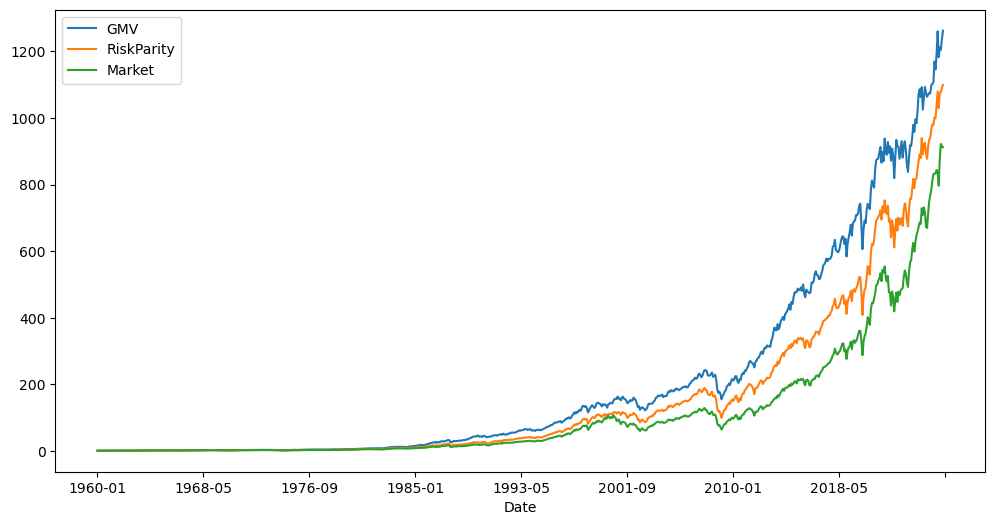

In [200]:
(btr_bench+1).cumprod().plot(figsize = (12,6))

In [201]:
btr_comparison = btr_bench
btr_comparison["BL momentum"] = btr["BL momentum"]
pt.summary_stats(btr_comparison, riskfree_rate=rf)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
GMV,0.113199,0.125533,-0.313735,4.564495,0.051956,0.077117,0.580879,-0.381444
RiskParity,0.110891,0.142367,-0.452250,4.985727,0.061383,0.089487,0.512902,-0.472896
Market,0.107783,0.152765,-0.464296,4.664148,0.067104,0.095400,0.469677,-0.500086
BL momentum,0.118700,0.151070,-0.616128,5.294456,0.066639,0.096203,0.539127,-0.504560


<Axes: xlabel='Date'>

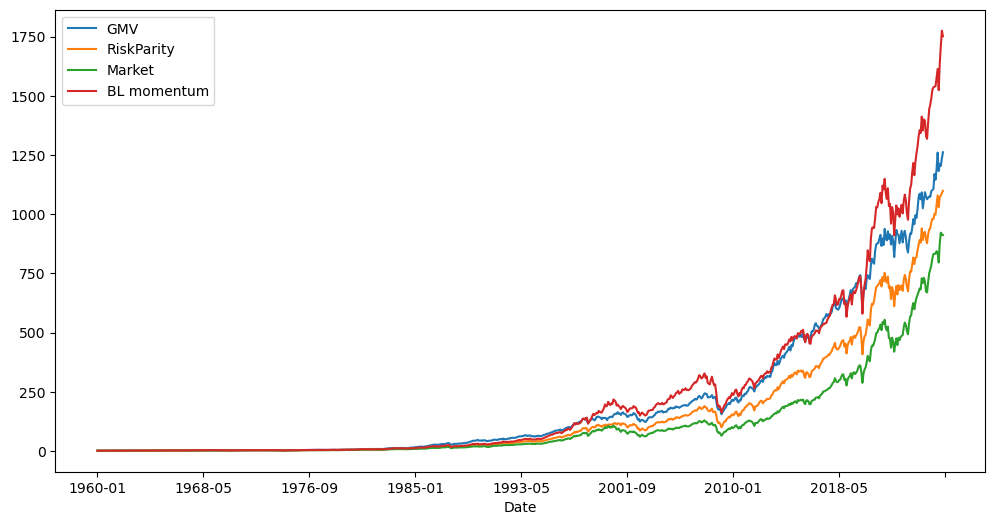

In [202]:
(btr_comparison+1).cumprod().plot(figsize = (12,6))

### Benchmark Comparison — Final Takeaway

The benchmark comparison provides a useful reference point for evaluating the Black–Litterman momentum strategy.

- **BL Momentum** delivers the highest annualized return at **11.87%**.
- **GMV** achieves the strongest risk-adjusted performance, with the highest Sharpe ratio of **0.581** and substantially lower volatility of **12.55%**.
- **Risk Parity** lies between GMV and the market, reducing volatility while maintaining a slightly higher return than the market portfolio.

Overall, the comparison highlights an important distinction:

> **BL Momentum generates the strongest return despite low predictive power of the view function, while GMV provides the strongest defensive and risk-adjusted performance.**

This also illustrates that successful view generation does not necessarily dominate covariance-based allocation on every dimension. Momentum views improve expected-return information and terminal wealth, while GMV benefits from focusing purely on risk structure.

### Again, Stage 1 establishes transparent benchmark models and shows that simple systematic views contain only very modest to "no" predictive power, which was very well expected.

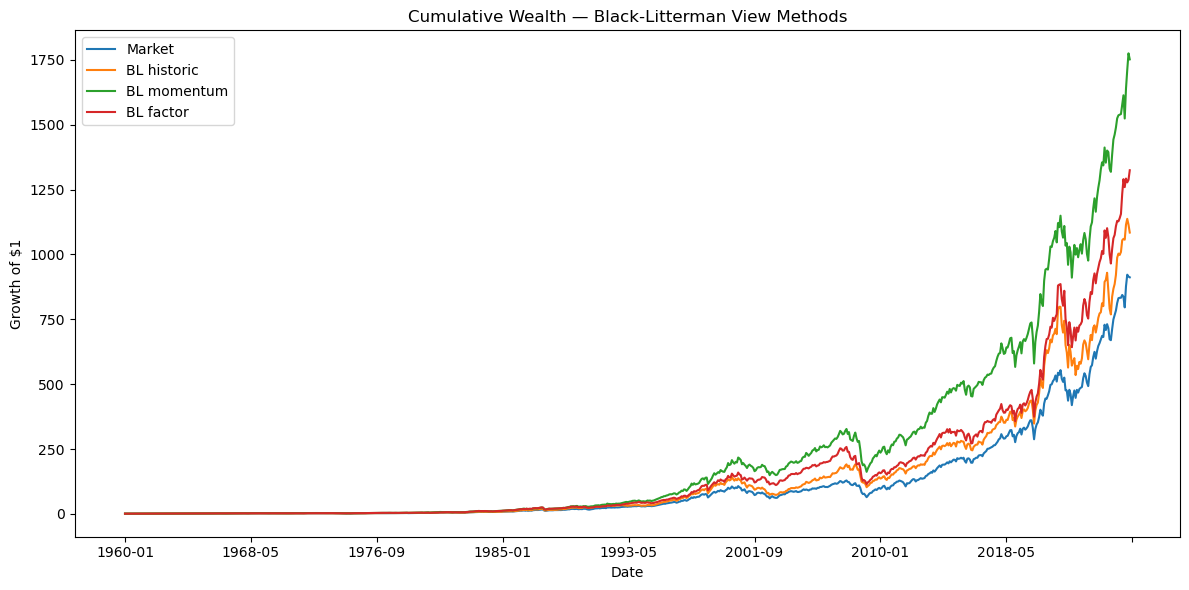

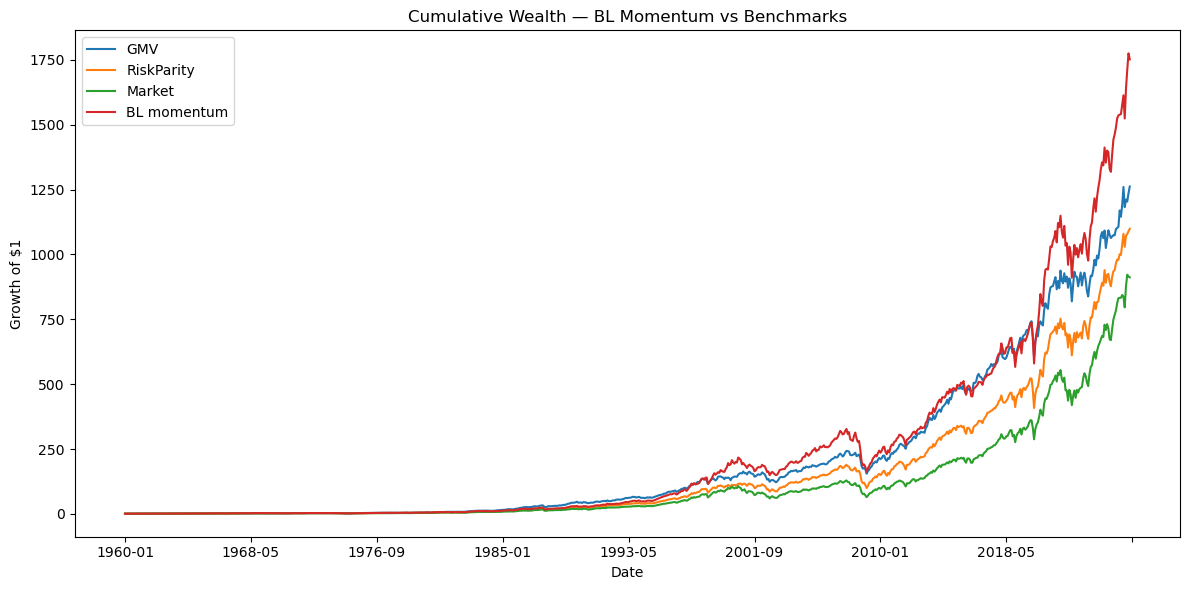

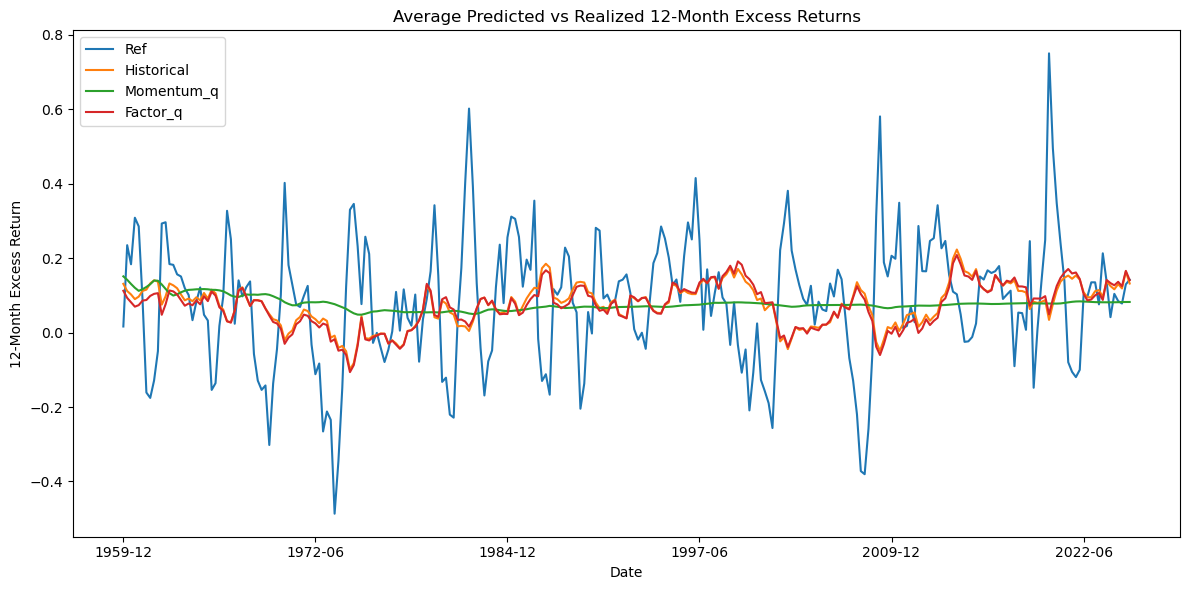

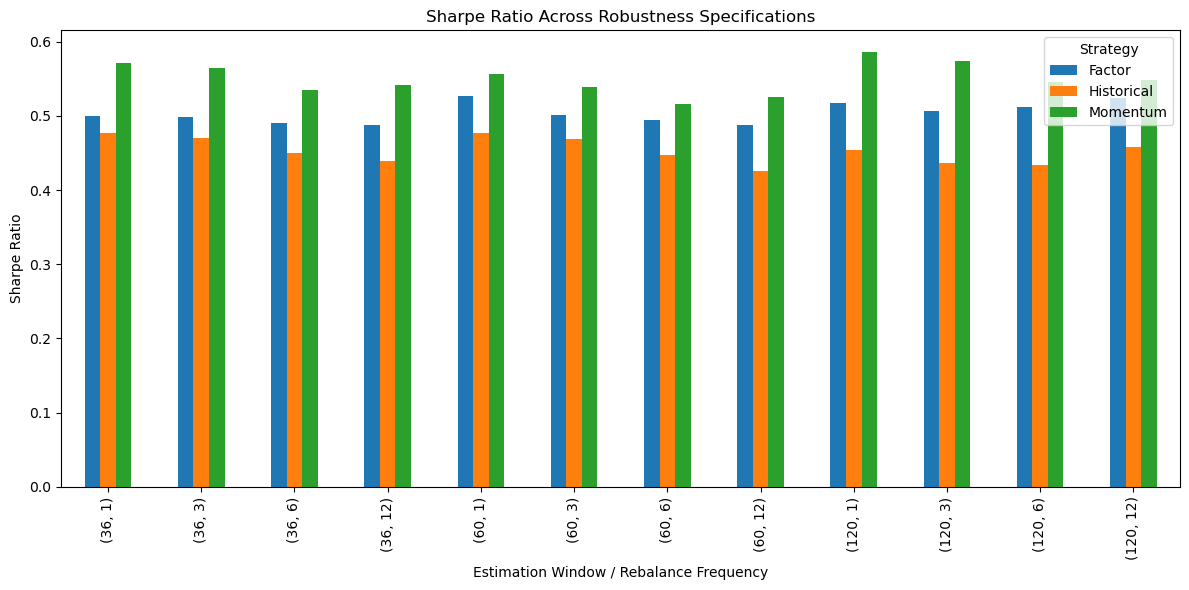

Stage 1 results exported successfully.


In [207]:
results_dir = Path("../data/results")
tables_dir = results_dir / "tables"
figures_dir = results_dir / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Main BL view-method comparison
# ------------------------------------------------------------

view_methods_summary = pt.summary_stats(
    btr_summary,
    riskfree_rate=rf_btr
)

view_methods_summary.to_csv(
    tables_dir / "view_methods_summary.csv"
)


# ------------------------------------------------------------
# 2. Forecast-quality metrics
# ------------------------------------------------------------

forecast_quality_summary = forecast_comparison.join(
    bucket_comparison
)

forecast_quality_summary.to_csv(
    tables_dir / "forecast_quality_summary.csv"
)


# ------------------------------------------------------------
# 3. Robustness results
# ------------------------------------------------------------

robustness.to_csv(
    tables_dir / "robustness_full.csv",
    index=False
)

robust_summary.to_csv(
    tables_dir / "robustness_summary.csv"
)


# ------------------------------------------------------------
# 4. Benchmark comparison
# ------------------------------------------------------------

benchmark_summary = pt.summary_stats(
    btr_comparison,
    riskfree_rate=rf
)

benchmark_summary.to_csv(
    tables_dir / "benchmark_summary.csv"
)


# ============================================================
# FIGURES
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 5. BL view methods cumulative wealth
# ------------------------------------------------------------

ax = (btr_summary + 1).cumprod().plot(figsize=(12, 6))

ax.set_title("Cumulative Wealth — Black-Litterman View Methods")
ax.set_ylabel("Growth of $1")
ax.set_xlabel("Date")

plt.tight_layout()
plt.savefig(
    figures_dir / "view_methods_wealth.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 6. Benchmark cumulative wealth
# ------------------------------------------------------------

ax = (btr_comparison + 1).cumprod().plot(figsize=(12, 6))

ax.set_title("Cumulative Wealth — BL Momentum vs Benchmarks")
ax.set_ylabel("Growth of $1")
ax.set_xlabel("Date")

plt.tight_layout()
plt.savefig(
    figures_dir / "benchmark_wealth.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 7. Forecast vs realized return level
# ------------------------------------------------------------

ax = q_eval_2.plot(figsize=(12, 6))

ax.set_title("Average Predicted vs Realized 12-Month Excess Returns")
ax.set_ylabel("12-Month Excess Return")
ax.set_xlabel("Date")

plt.tight_layout()
plt.savefig(
    figures_dir / "forecast_vs_realized.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 8. Robustness: Sharpe ratios
# ------------------------------------------------------------

sharpe_pivot = robustness.pivot_table(
    index=["Window", "Rebalance"],
    columns="Strategy",
    values="Sharpe"
)

ax = sharpe_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Sharpe Ratio Across Robustness Specifications")
ax.set_ylabel("Sharpe Ratio")
ax.set_xlabel("Estimation Window / Rebalance Frequency")

plt.tight_layout()
plt.savefig(
    figures_dir / "robustness_sharpe.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("Stage 1 results exported successfully.")